# 10장. 회귀분석 (1) 자동차 연비 예측 분석

In [96]:
!pip install scikit-learn

# 4. 데이터 준비 및 탐색

In [97]:
import numpy as np
import pandas as pd

data_df = pd.read_csv('./10장_data/auto-mpg.csv', header = 0, engine = 'python')

In [98]:
print('데이터셋 크기: ', data_df.shape)
data_df.head()

데이터셋 크기:  (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [99]:
data_df = data_df.drop(['car_name', 'origin', 'horsepower'], axis = 1, inplace = False)
data_df.head()  #작업 확인용 출력

,mpg,cylinders,displacement,weight,acceleration,model_year
0,18.0,8,307.0,3504,12.0,70
1,15.0,8,350.0,3693,11.5,70
2,18.0,8,318.0,3436,11.0,70
3,16.0,8,304.0,3433,12.0,70
4,17.0,8,302.0,3449,10.5,70


In [100]:
print('데이터셋 크기: ', data_df.shape)

데이터셋 크기:  (398, 6)


In [101]:
data_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   weight        398 non-null    int64  
 4   acceleration  398 non-null    float64
 5   model_year    398 non-null    int64  
dtypes: float64(3), int64(3)
memory usage: 18.8 KB


# 5. 분석 모델 구축, 결과 분석 및 시각화

## 5.1 선형 회귀 분석 모델 구축하기

In [102]:
! pip install scikit-learn

In [103]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import sklearn

In [104]:
#X, Y 분할하기
Y = data_df['mpg']
X = data_df.drop(['mpg'], axis = 1, inplace = False)

In [105]:
#훈련용 데이터와 평가용 데이터 분할하기
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state = 0)

In [106]:
#선형 회귀 분석 : 모델 생성
lr = LinearRegression()

In [107]:
#선형 회귀 분석 : 모델 훈련
import sklearn
sklearn.set_config(display='text')
lr.fit(X_train.values, Y_train)

LinearRegression()

In [108]:
#선형 회귀 분석 : 평가 데이터에 대한 예측 수행 -> 예측 결과 Y_predict 구하기
Y_predict = lr.predict(X_test.values)

### - 평가 지표를 사용하여 선형 회귀 분석 모델 평가하기

In [109]:
mse = mean_squared_error(Y_test, Y_predict)
rmse = np.sqrt(mse)
print('MSE : {0:.3f}, RMSE : {1:.3f}'.format(mse, rmse))
print('R^2(Variance score) : {0:.3f}'.format(r2_score(Y_test, Y_predict)))

MSE : 12.278, RMSE : 3.504
R^2(Variance score) : 0.808


### - 각 피처의 회귀 계수 확인

In [110]:
#sklean에서 결과로 나오는 값들은 무조건 뒤에 _붙이기로 약속함
#y=ax+b 라는 일차식이 있으면 여기서 b가 ir.intercept_이고 최소 연비? 라고 생각하면 될듯
print('Y 절편 값: ', np.round(lr.intercept_, 2))
#여러개의 a1,a2,a3의 값이다-> 기울기를 결정하는 값?
print('회귀 계수 값: ', np.round(lr.coef_, 2))

Y 절편 값:  -17.55
회귀 계수 값:  [-0.14  0.01 -0.01  0.2   0.76]


In [111]:
coef = pd.Series(data = np.round(lr.coef_, 2), index = X.columns)
coef.sort_values(ascending = False)

model_year      0.76
acceleration    0.20
displacement    0.01
weight         -0.01
cylinders      -0.14
dtype: float64

## 5.2 회귀 분석 결과를 산점도 + 선형 회귀 그래프로 시각화하기

In [112]:
import matplotlib.pyplot as plt
import seaborn as sns

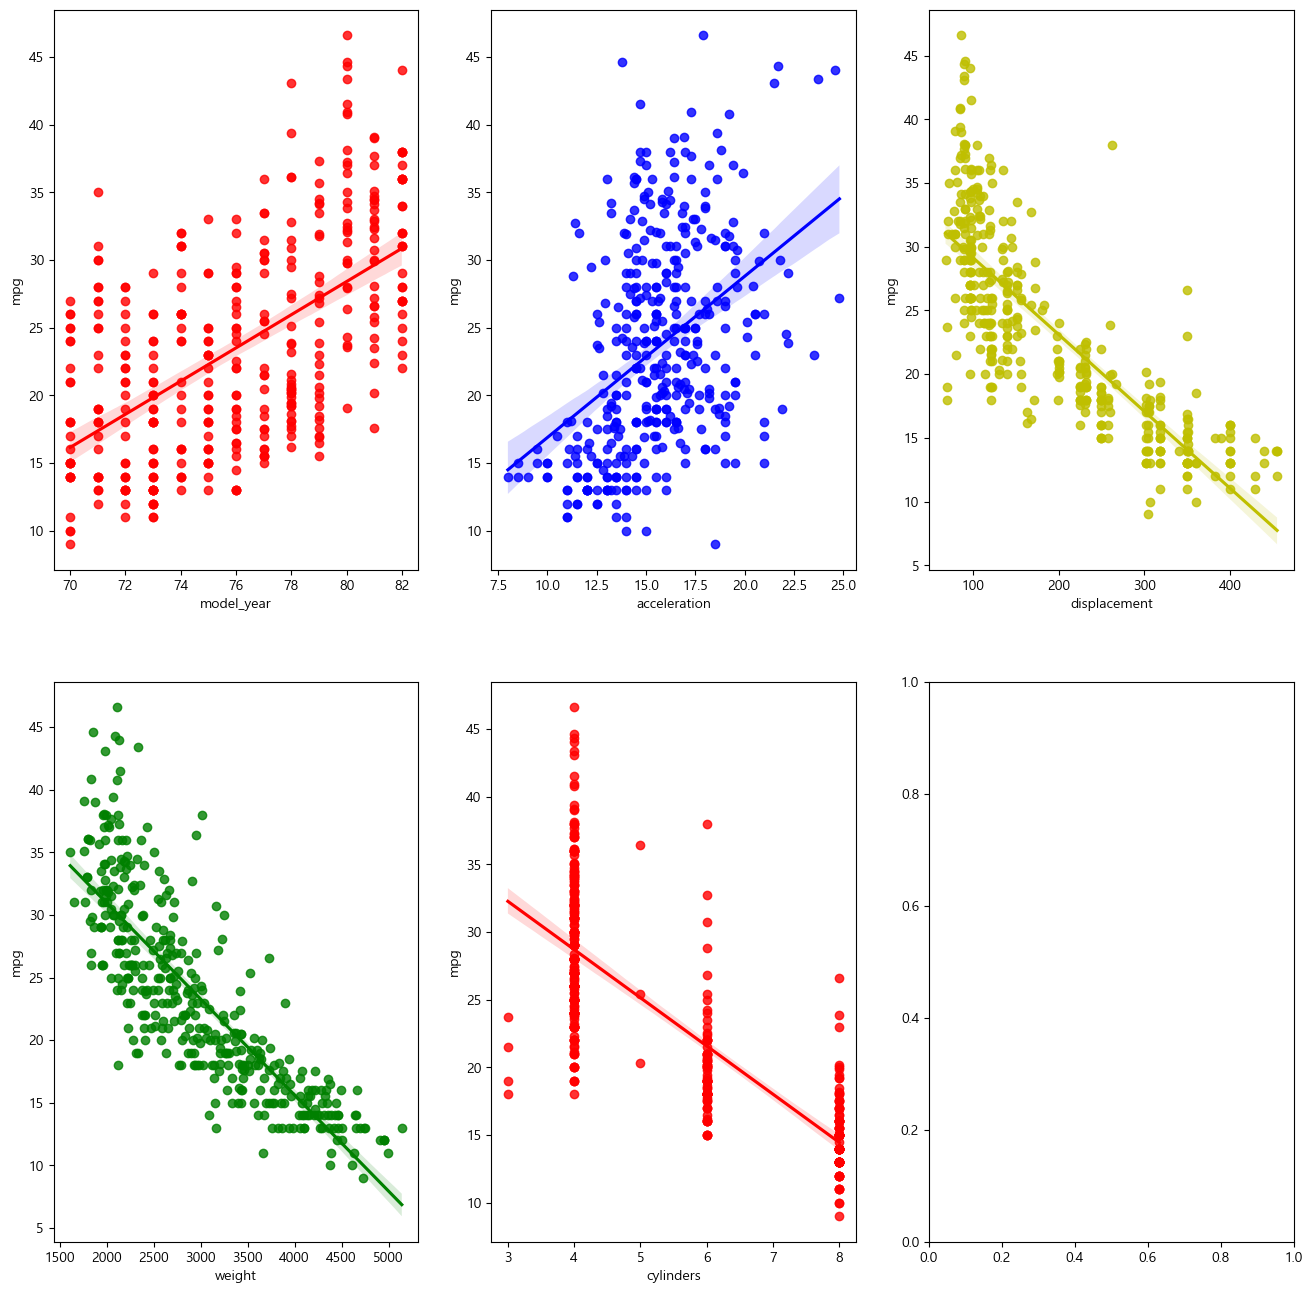

In [113]:
fig, axs = plt.subplots(figsize = (16, 16), nrows = 2, ncols = 3)
x_features = ['model_year', 'acceleration', 'displacement', 'weight', 'cylinders']
plot_color = ['r', 'b', 'y', 'g', 'r']
for i, feature in enumerate(x_features):
    row = int(i/3)
    col = i%3    
    #sns.regplot이 선형회귀를 해주는 함수라서 바로 계산이 되고 plot이 되는거다
    sns.regplot(x = feature, y = 'mpg', data = data_df, ax = axs[row][col], color = plot_color[i])

In [114]:
data_df.head(2)

,mpg,cylinders,displacement,weight,acceleration,model_year
0,18.0,8,307.0,3504,12.0,70
1,15.0,8,350.0,3693,11.5,70


### 연비 예측하기 

In [115]:
print("연비를 예측하고 싶은 차의 정보를 입력해주세요.")

cylinders = int(input("cylinders : "))
displacement = int(input("displacement : "))
weight = int(input("weight : "))
acceleration = int(input("acceleration : "))
model_year = int(input("model_year : "))

연비를 예측하고 싶은 차의 정보를 입력해주세요.


ValueError: invalid literal for int() with base 10: ''

In [ ]:
mpg_predict = lr.predict([[cylinders, displacement, weight, acceleration, model_year]])

In [ ]:
print("이 자동차의 예상 연비(MPG)는 %.2f입니다." % mpg_predict)

이 자동차의 예상 연비(MPG)는 -13.62입니다.


C:\Users\user\AppData\Local\Temp\ipykernel_26468\3712939959.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print("이 자동차의 예상 연비(MPG)는 %.2f입니다." % mpg_predict)


In [ ]:
# 활용문제! 
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler

data = fetch_california_housing()
columns = data.feature_names
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
df = df[df['AveRooms'] < df['AveRooms'].quantile(0.99)]
df = df[df['AveOccup'] < df['AveOccup'].quantile(0.99)]
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
#AveRooms의 경우는 0.8~141.9 로 큰 비율 차이를 갖고 있는것을 볼 수있다.
#이것은 해당 지역의 방개수/ 동네 전체 가구 수 
#avebedrms는 침실개수 / 동네 가구 수 이다.
#큰 차이가 나는 이유는 

In [122]:
#방들 중 침실이 차지하는 비율
df['BedRoomRatio'] = df['AveBedrms'] / df['AveRooms']
#사람당 방 개수
df['RoomsPerPerson'] = df['AveRooms'] / df['AveOccup']

In [141]:
df.agg(['min','max','mean']).head(3)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.750000,32.540000,-124.350000,0.149990
max,15.000100,52.000000,10.352941,3.411111,28566.000000,5.392954,41.950000,-114.550000,5.000010
mean,3.873765,28.735021,5.286345,1.066745,1426.809868,2.893926,35.624621,-119.579373,2.075242


In [142]:
X = df.drop(columns=['target'])
Y = df['target']
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(data=X_scaled_array, columns=X.columns)
X_scaled.agg(['min', 'max','mean'])

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
min,-1.784734e+00,-2.206536e+00,-3.601767e+00,-5.648254e+00,-1.297307e+00,-3.084725e+00,-1.447822e+00,-2.379809e+00
max,5.885697e+00,1.850909e+00,4.109891e+00,1.805477e+01,2.472792e+01,3.595654e+00,2.968931e+00,2.508884e+00
mean,7.306352e-17,6.744325e-17,-1.124054e-17,-2.034538e-15,1.095953e-16,-5.451663e-16,1.011649e-15,-1.291538e-14


In [125]:
df['AveBedrms'].head()

0    1.023810
1    0.971880
2    1.073446
3    1.073059
4    1.081081
Name: AveBedrms, dtype: float64

In [127]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'target', 'BedRoomRatio', 'RoomsPerPerson'],
      dtype='object')

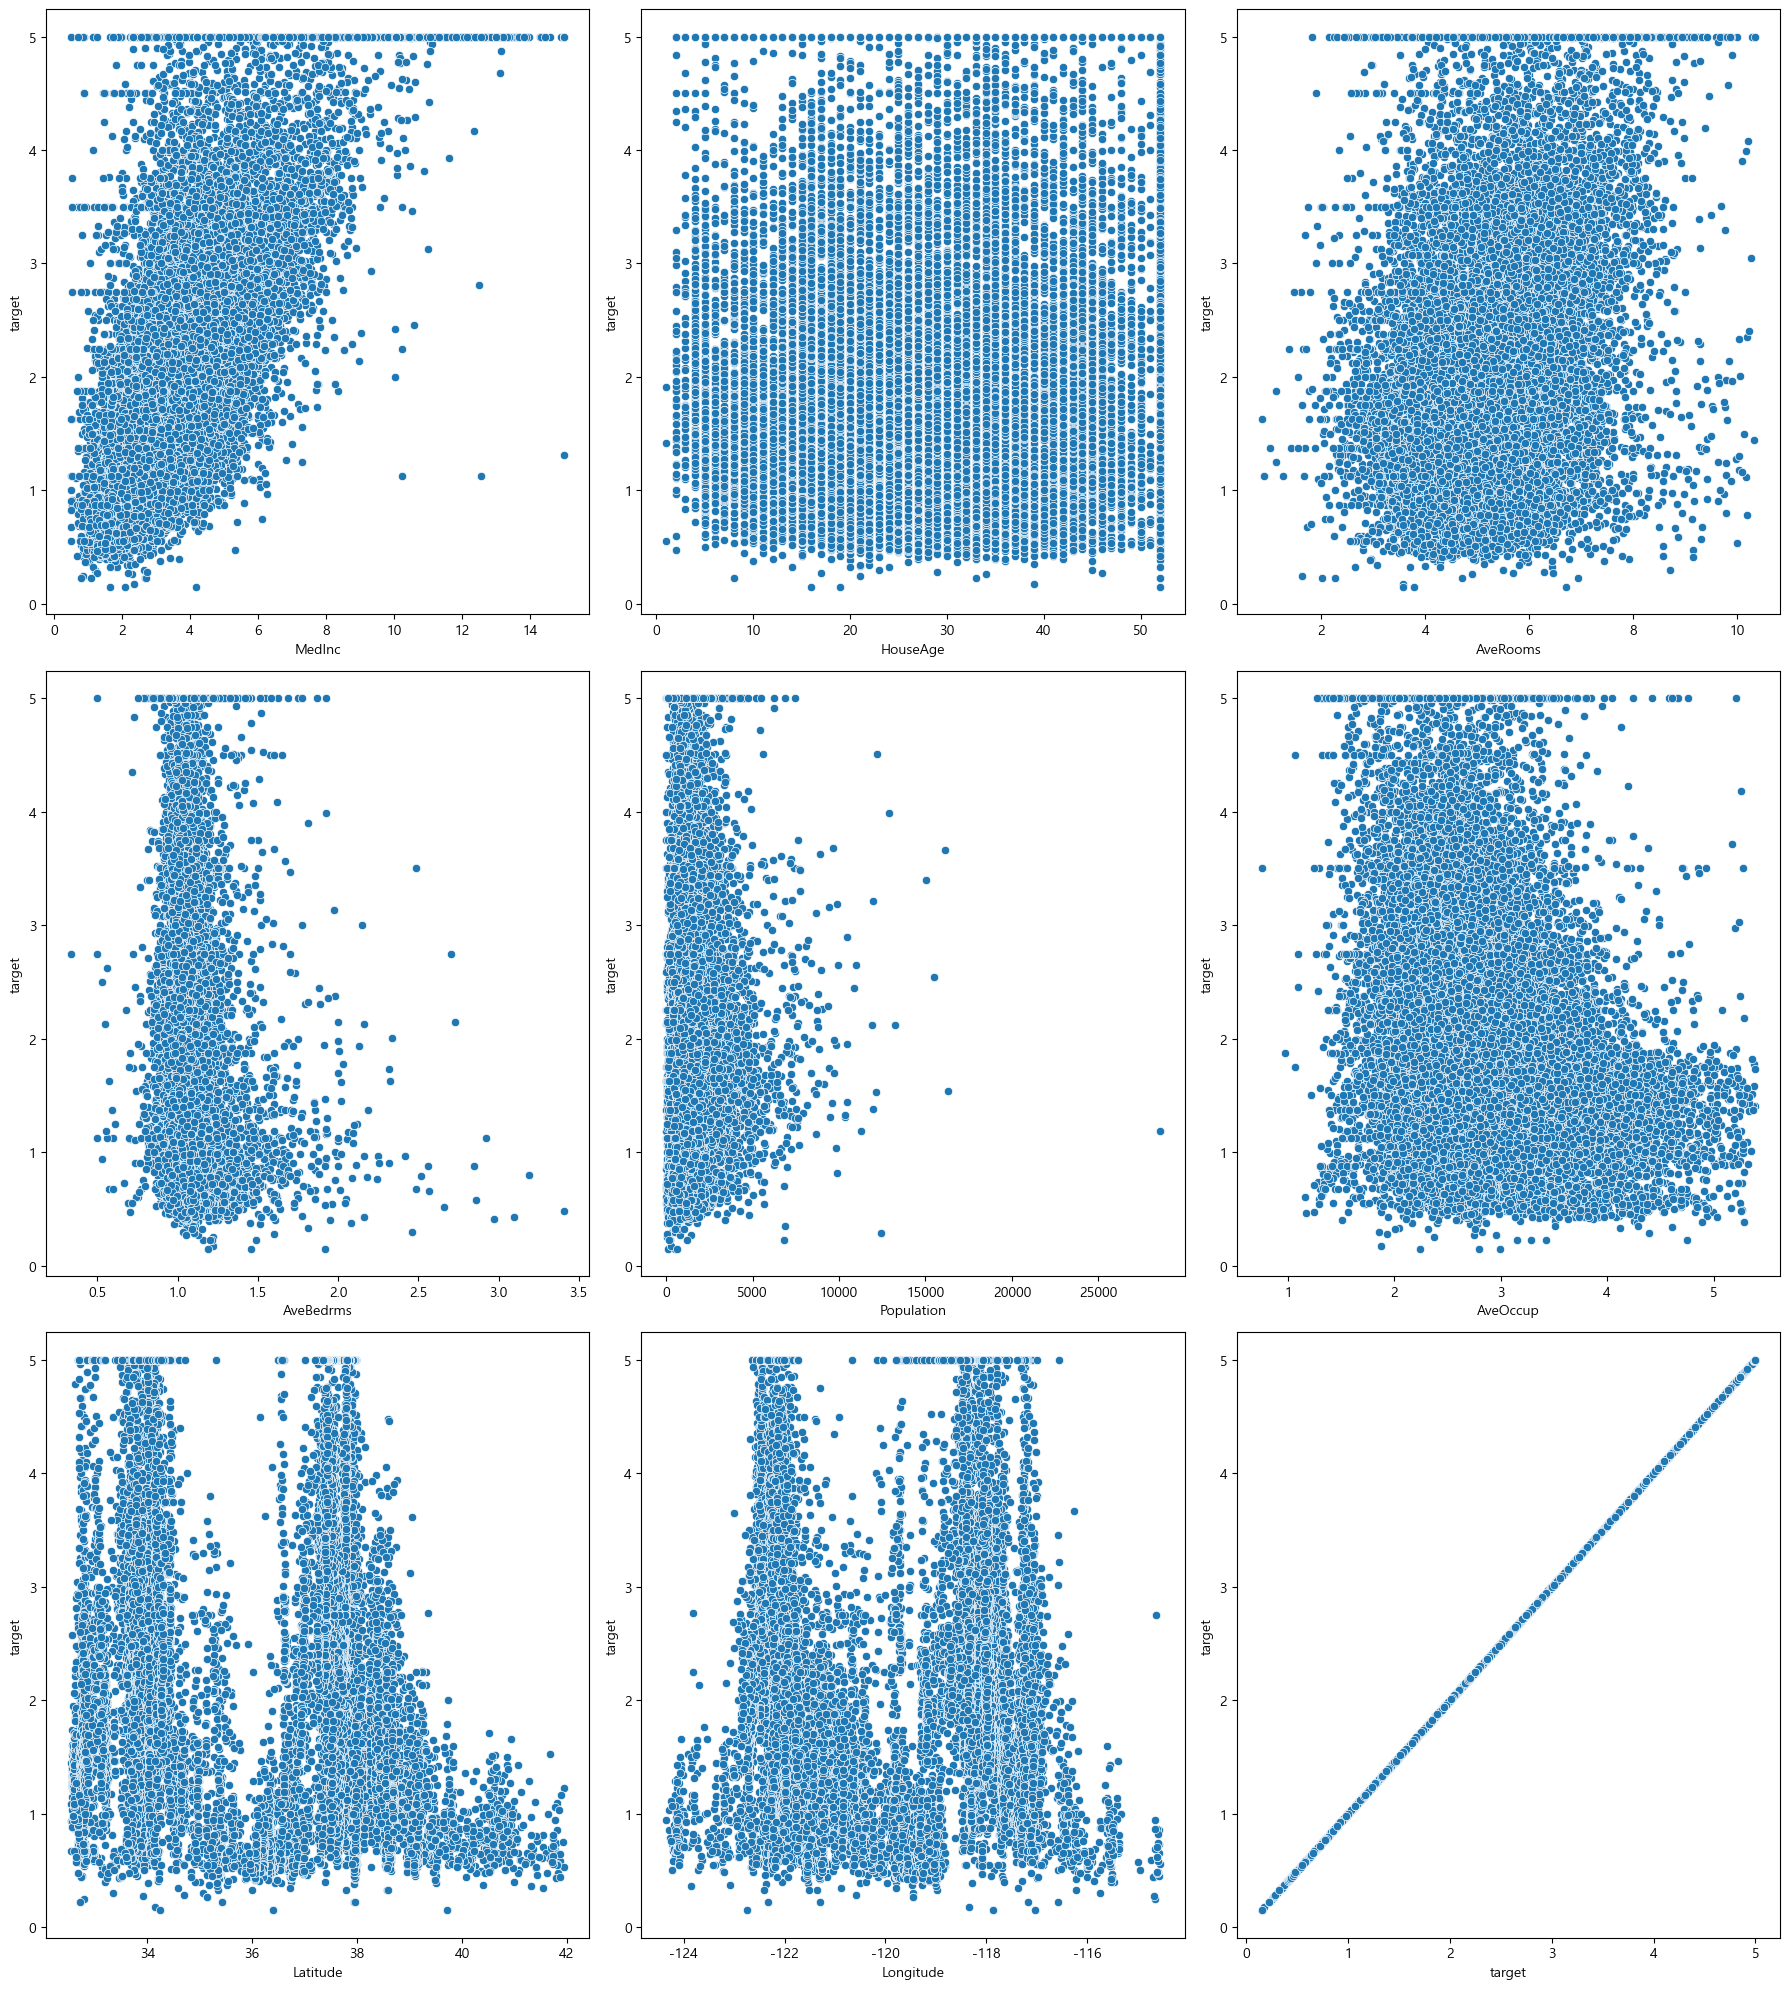

In [143]:
#Scatterplot
features = df.columns

fig, axs = plt.subplots(3, 3, figsize=(18, 20))

for i, feature in enumerate(features):
    row = i // 3
    col = i % 3

    sns.scatterplot(
        x=feature,
        y='target',
        data=df,
        ax=axs[row][col]
    )
    
plt.tight_layout()
plt.show()

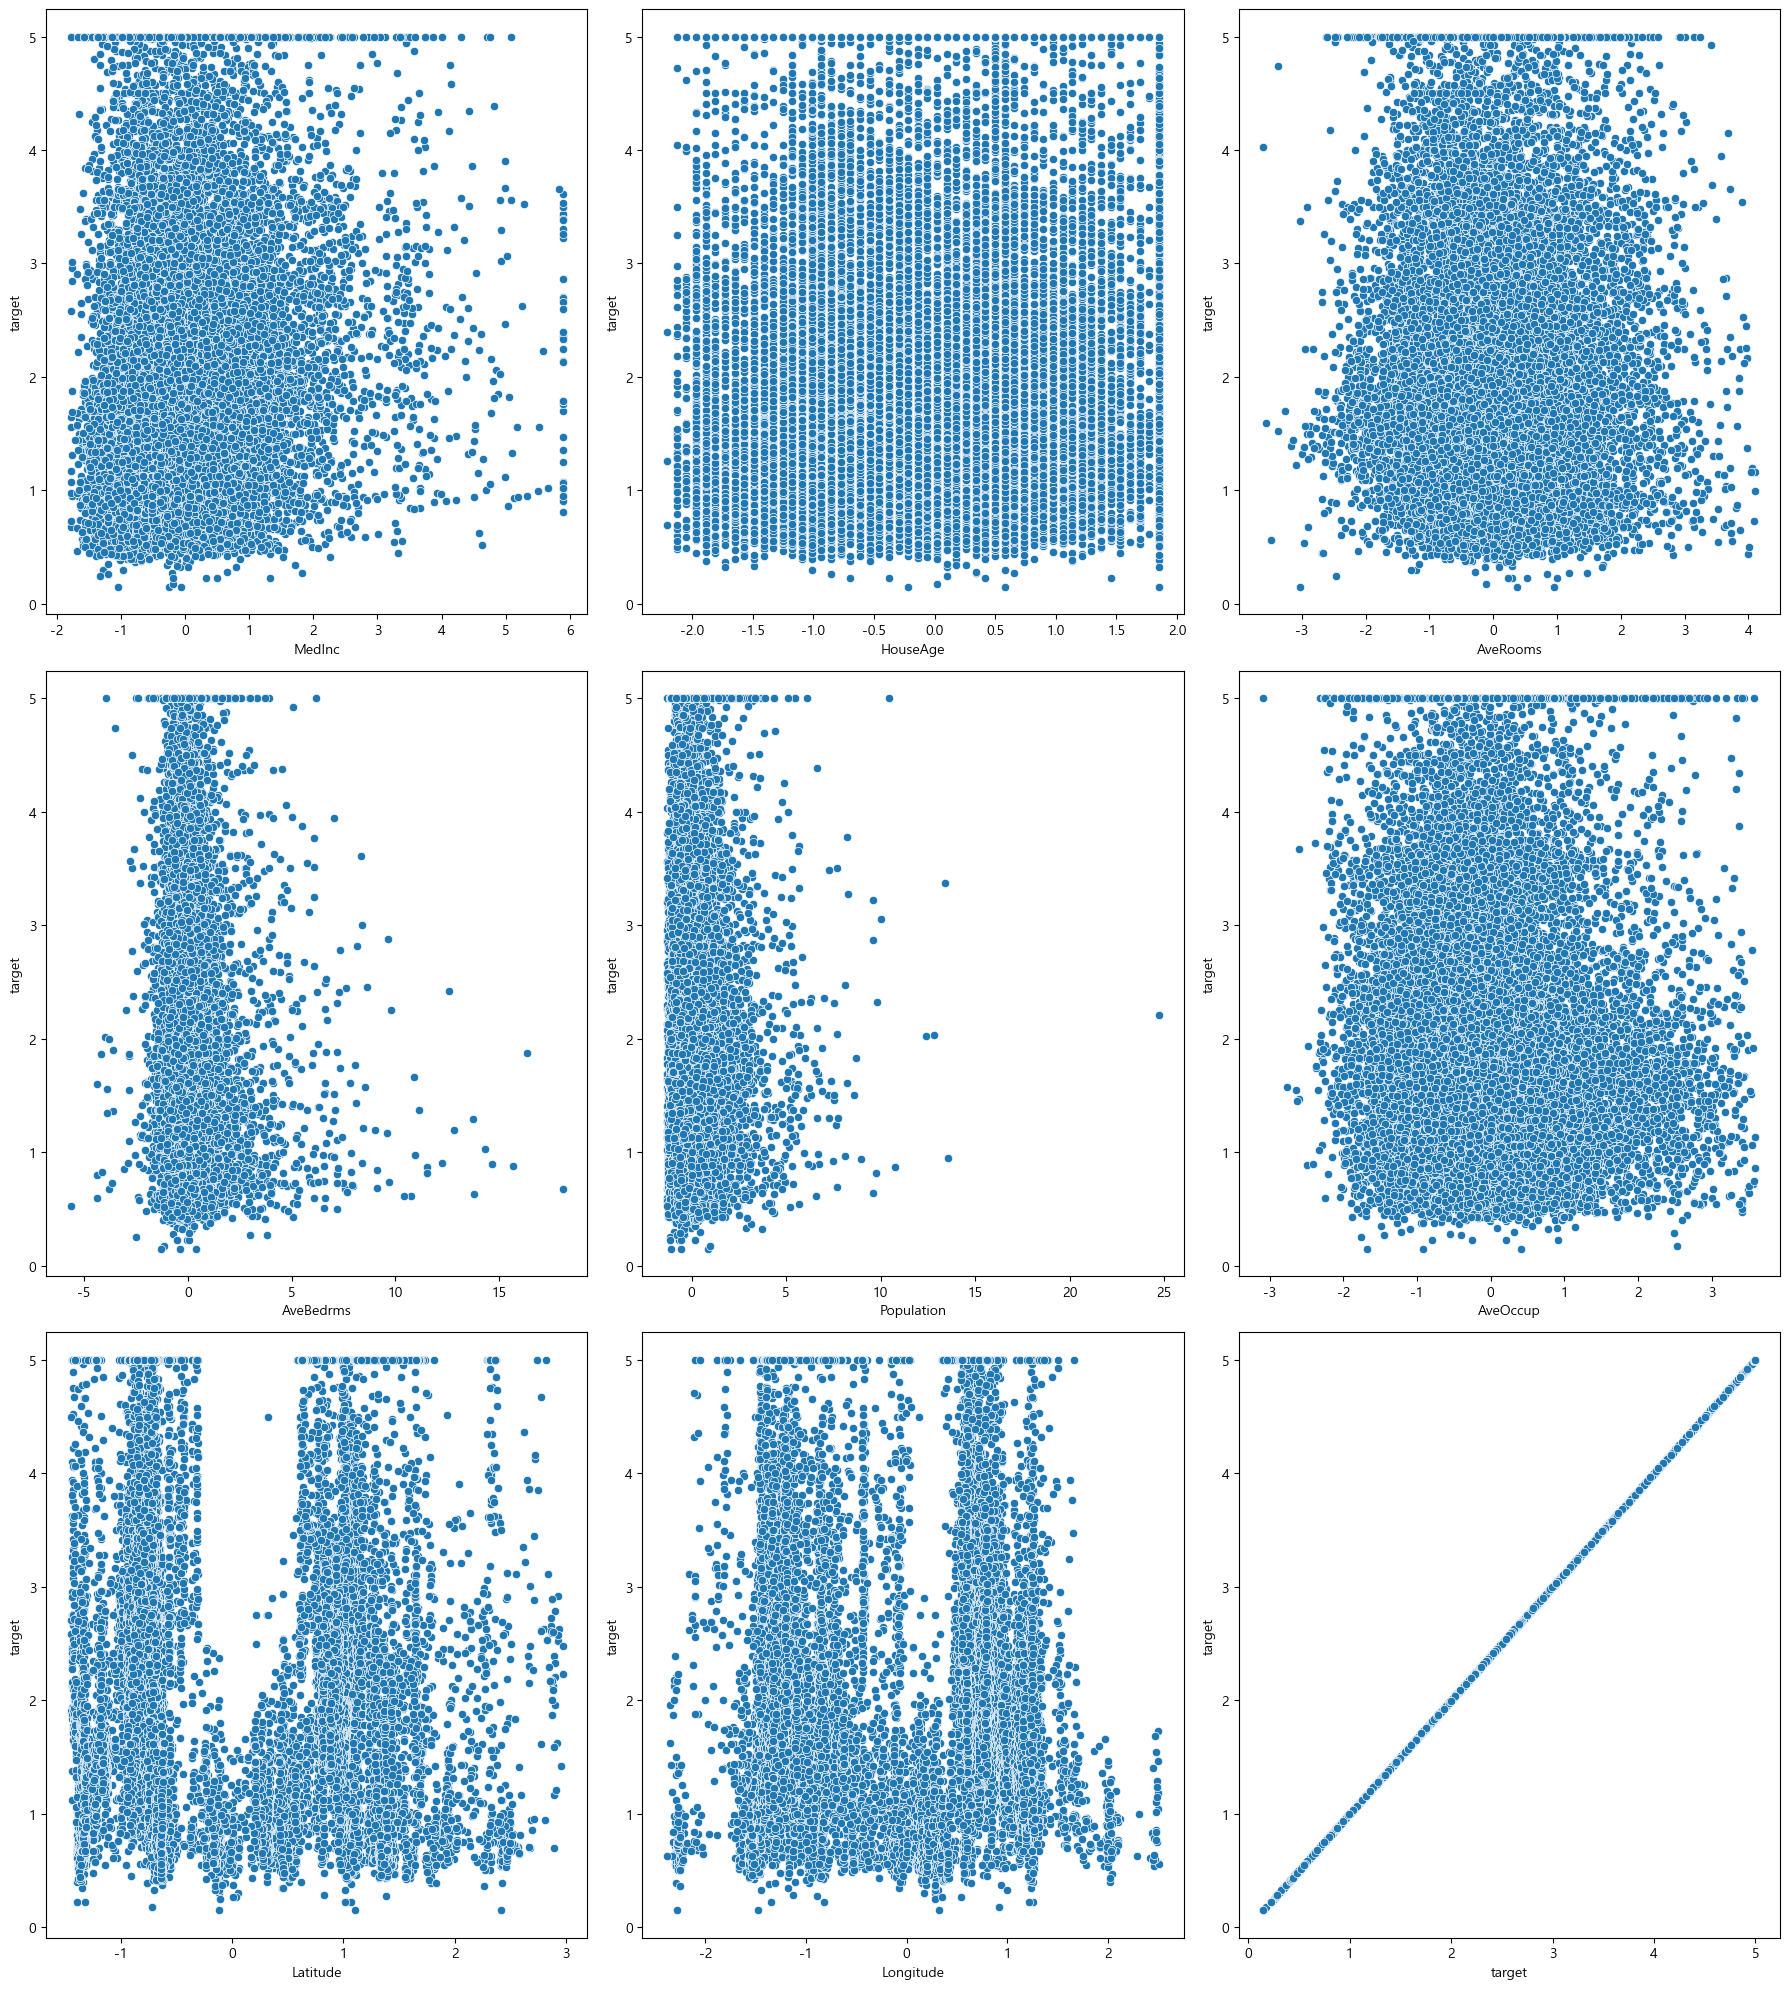

In [151]:
#Scatterplot
features = df.columns
X_scaled['target'] = df['target']

fig, axs = plt.subplots(3, 3, figsize=(18, 20))

for i, feature in enumerate(features):
    row = i // 3
    col = i % 3

    sns.scatterplot(
        x=feature,
        y='target',
        data=X_scaled,
        ax=axs[row][col]
    )
    
plt.tight_layout()
plt.show()

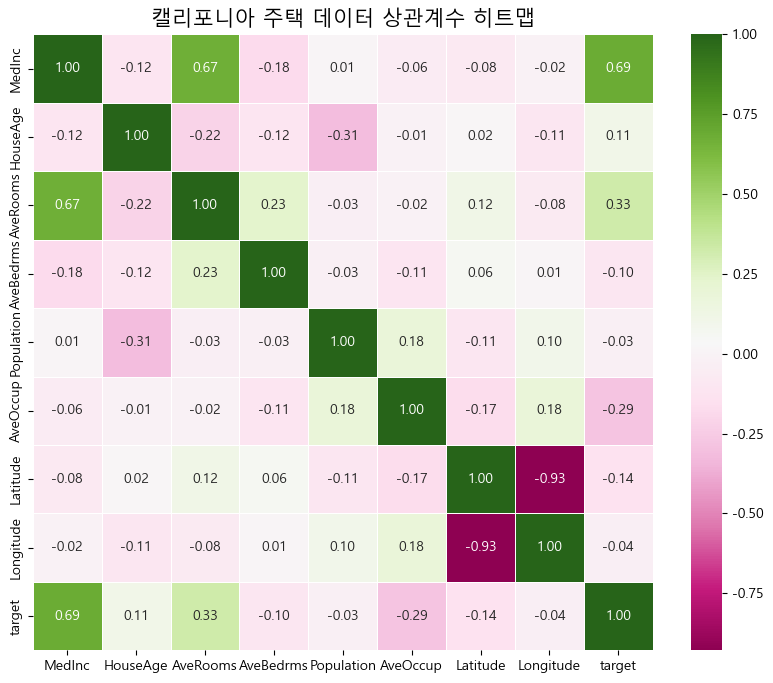

In [145]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='PiYG', fmt=".2f", linewidths=0.5)

plt.title('캘리포니아 주택 데이터 상관계수 히트맵', fontsize=15)
plt.show()
#각각의 컬럼들이 상관관계를 갖는다. 
#latitude와 longituded는 위도와 경도로 캘리포니아가 대각선 형태로 생겨서 북쪽으로 갈수록 위도는 커지고 경도는 작아지게 되서 그렇다.
#중위 소득이 높아지면 집값도 대부분 높아지므로 0.69의 높은 상관관계를 갖는다.

In [ ]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'target'],
      dtype='object')

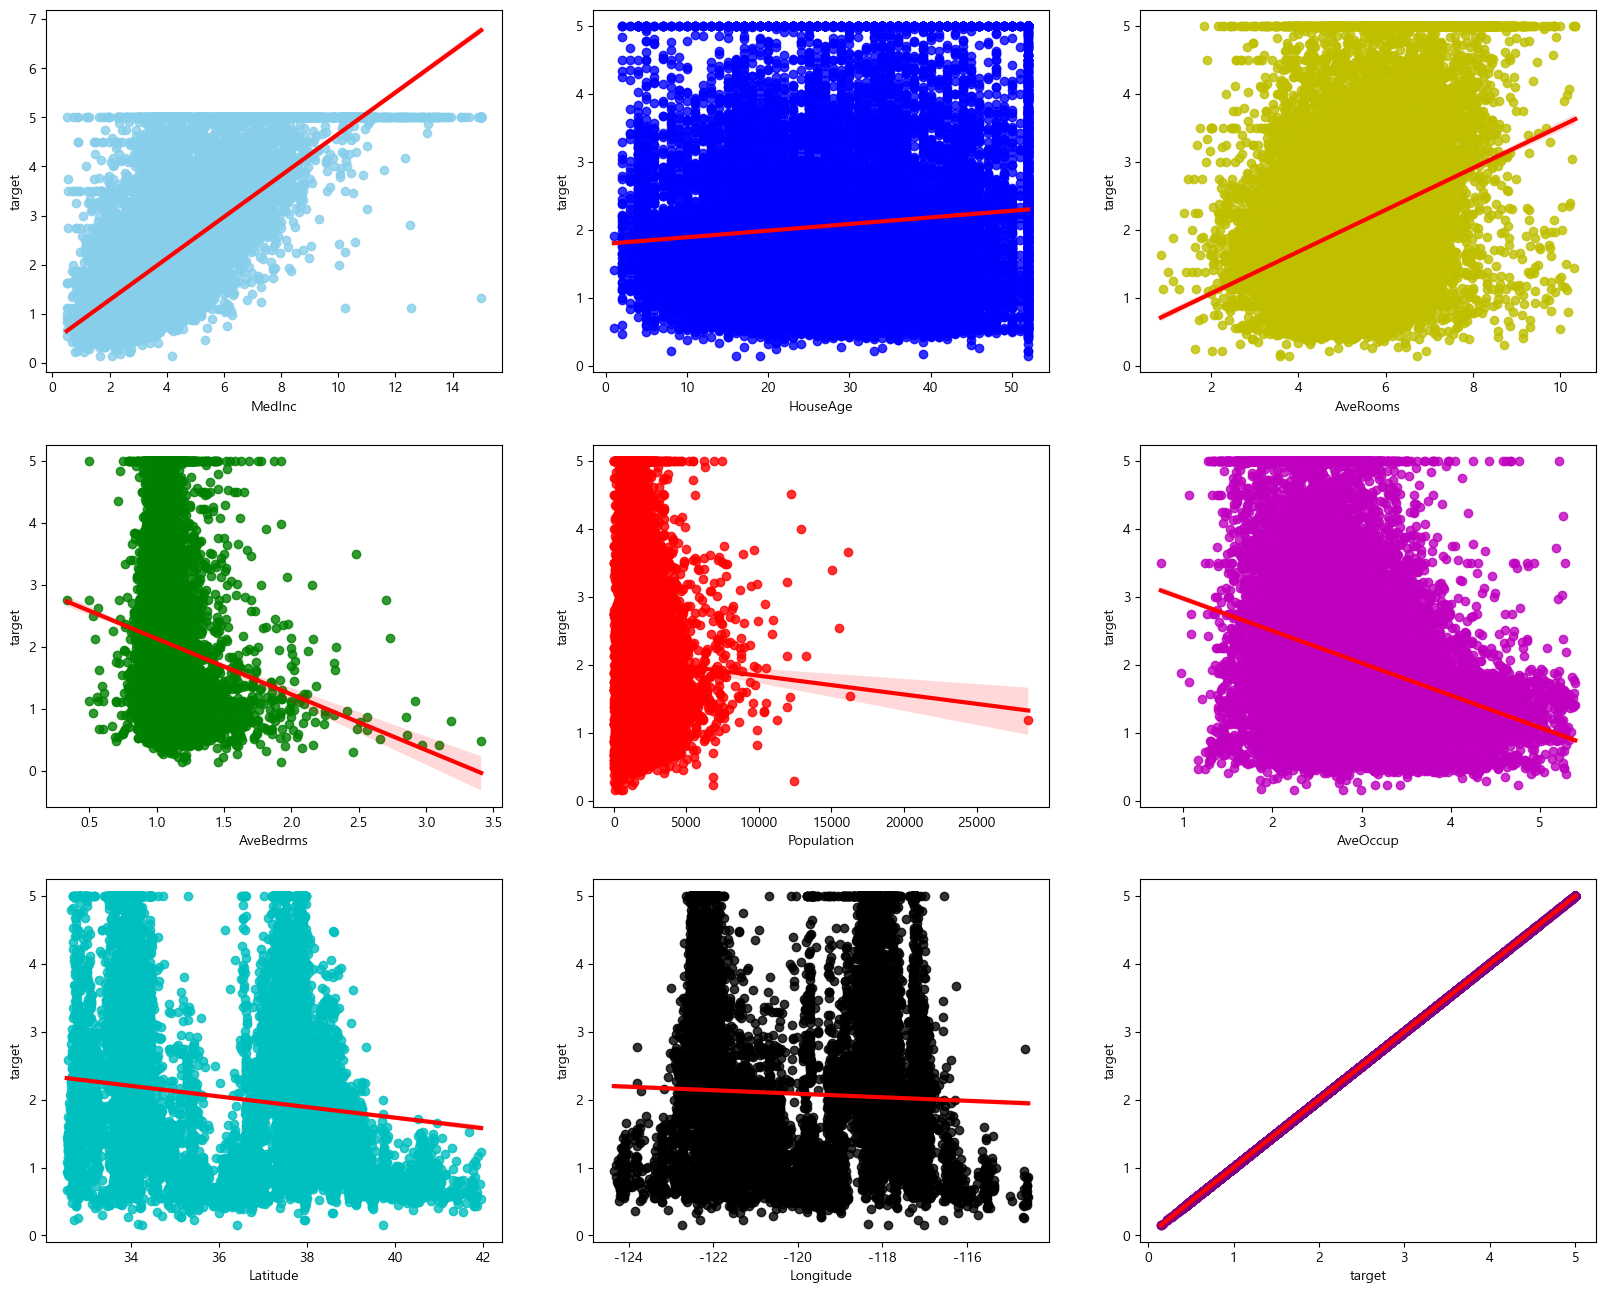

In [155]:
fig, axs = plt.subplots(figsize = (20, 16), nrows = 3, ncols = 3)
x_features = df.columns
# x_features = ['MedInc','HouseAge', 'AveRooms', 'AveBedrms' ,'Population', 'AveOccup', 'Latitude', 'Longitude']
plot_color = ['skyblue', 'b', 'y', 'g', 'r', 'm', 'c', 'k' , 'purple']
for i, feature in enumerate(x_features):
    row = int(i/3)
    col = i%3    
    #sns.regplot이 선형회귀를 해주는 함수라서 바로 계산이 되고 plot이 되는거다
    sns.regplot(x = feature, y = 'target', data = df, ax = axs[row][col], color = plot_color[i],line_kws={'color': 'red', 'lw': 3})

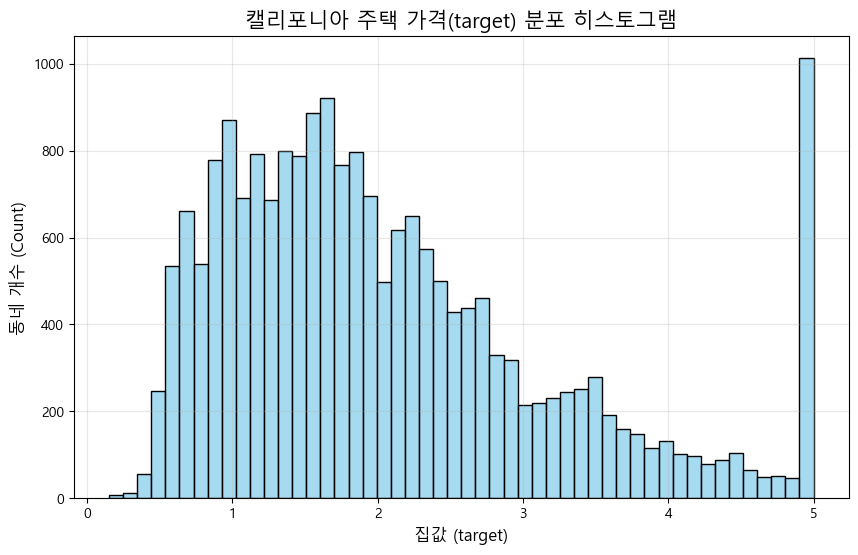

In [147]:
plt.figure(figsize=(10, 6))

# kde=True를 주면 막대그래프 위에 부드러운 분포 곡선선까지 같이 그려줍니다!
sns.histplot(df['target'], color='skyblue', bins=50)

plt.title('캘리포니아 주택 가격(target) 분포 히스토그램', fontsize=15)
plt.xlabel('집값 (target)', fontsize=12)
plt.ylabel('동네 개수 (Count)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

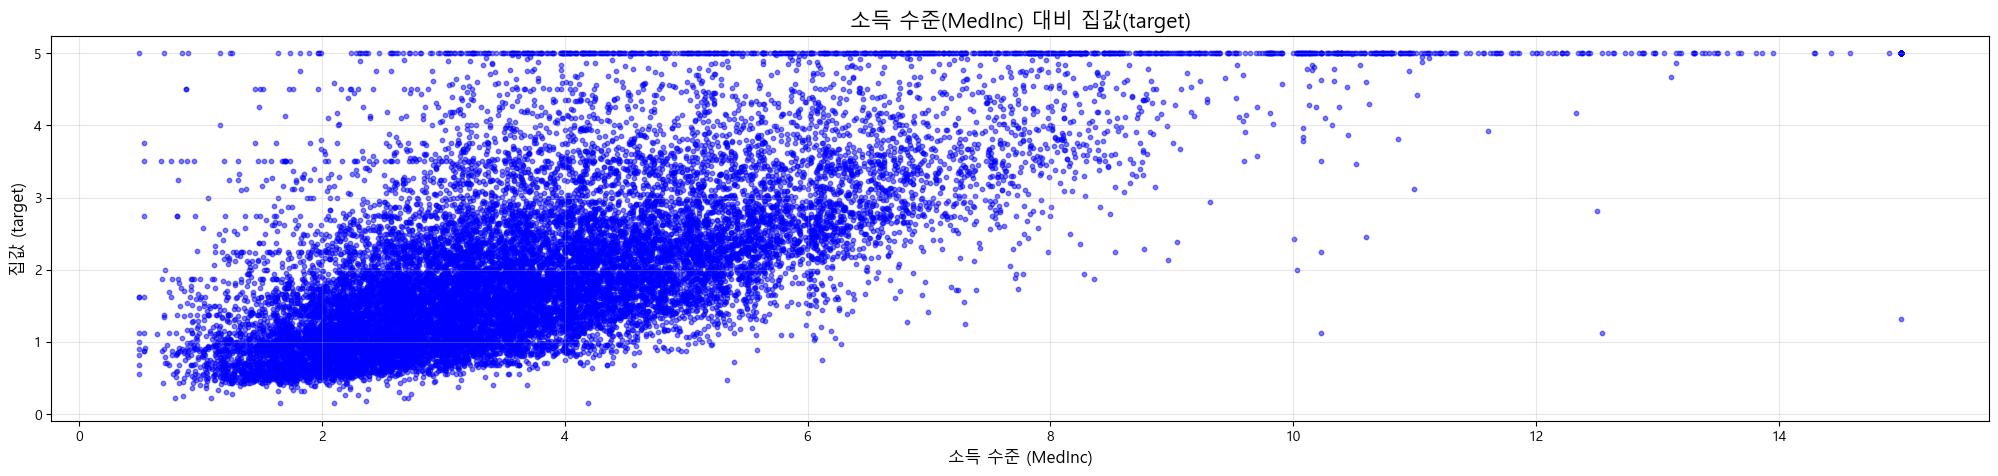

In [148]:
plt.rcParams["figure.figsize"] = (25, 5)
plt.scatter(df['MedInc'], df['target'], s=10, color='blue', alpha=0.5)
plt.title('소득 수준(MedInc) 대비 집값(target)', fontsize=15)
plt.xlabel('소득 수준 (MedInc)', fontsize=12)
plt.ylabel('집값 (target)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

In [149]:
# X_scaled.isna().sum()
df.isna().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
target        0
dtype: int64

In [201]:
#X, Y 분할하기
Y = df['target']
X = df.drop(['target'], axis = 1, inplace = False)
#훈련용 데이터와 평가용 데이터 분할하기
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 8)
lr = LinearRegression()
sklearn.set_config(display='text')
lr.fit(X_train.values, Y_train)
#선형 회귀 분석 : 평가 데이터에 대한 예측 수행 -> 예측 결과 Y_predict 구하기
Y_predict = lr.predict(X_test.values)
mse = mean_squared_error(Y_test, Y_predict)
rmse = np.sqrt(mse)
print('MSE : {0:.3f}, RMSE : {1:.3f}'.format(mse, rmse))
print('R^2(Variance score) : {0:.3f}'.format(r2_score(Y_test, Y_predict)))

MSE : 0.418, RMSE : 0.646
R^2(Variance score) : 0.677


In [195]:
#X, Y 분할하기
Y = df['target']
X = df.drop(['target'], axis = 1, inplace = False)
#훈련용 데이터와 평가용 데이터 분할하기
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 8)

In [196]:
lr = LinearRegression()

In [197]:
#선형 회귀 분석 : 모델 훈련
import sklearn
sklearn.set_config(display='text')
lr.fit(X_train.values, Y_train)

LinearRegression()

In [193]:
#선형 회귀 분석 : 평가 데이터에 대한 예측 수행 -> 예측 결과 Y_predict 구하기
Y_predict = lr.predict(X_test.values)

In [194]:
mse = mean_squared_error(Y_test, Y_predict)
rmse = np.sqrt(mse)
print('MSE : {0:.3f}, RMSE : {1:.3f}'.format(mse, rmse))
print('R^2(Variance score) : {0:.3f}'.format(r2_score(Y_test, Y_predict)))
#결과값이 10만달러가 기준이므로 0.737이면 7.3만 달러 정도 평균적으로 오차가 발생하며
#59.3퍼센트 정도 설명력을 가지고 있다.

MSE : 0.436, RMSE : 0.660
R^2(Variance score) : 0.666


In [161]:
#sklean에서 결과로 나오는 값들은 무조건 뒤에 _붙이기로 약속함
#y=ax+b 라는 일차식이 있으면 여기서 b가 ir.intercept_이고 최소 연비? 라고 생각하면 될듯
print('Y 절편 값: ', np.round(lr.intercept_, 2))
#여러개의 a1,a2,a3의 값이다-> 기울기를 결정하는 값?
print('회귀 계수 값: ', np.round(lr.coef_, 2))

#y절편 값이 -36이라는 의미는 평균의 집들이 -36부터 시작하므로 비싼집들이 어마어마하게 비싸다는 뜻

Y 절편 값:  -34.65
회귀 계수 값:  [ 0.43  0.01 -0.09  0.85  0.   -0.4  -0.44 -0.43]


In [162]:
coef = pd.Series(data = np.round(lr.coef_, 2), index = X.columns)
coef.sort_values(ascending = False)
#침실의 개수와 소득이 집값과 큰 긍정적인 영향이 있고
#캘리포니아의 경우 해안가나 남부 대도시가 비싸서 위쪽과 내륙으로 갈수록 집값이 떨어진다
#이때 averooms 즉 평균 방의 갯수가 마이너스인 이유는 침실외의 불필요한 방의 갯수가 많은곳은
#오히려 집값이 낮아진다 라는 결론

AveBedrms     0.85
MedInc        0.43
HouseAge      0.01
Population    0.00
AveRooms     -0.09
AveOccup     -0.40
Longitude    -0.43
Latitude     -0.44
dtype: float64

#### MedInc — Median Income (중위 소득)
- 해당 지역(block group)의 중위 소득
- 단위는 10,000달러 단위

#### HouseAge — Housing Median Age (주택 중위 연식)
- 지역 내 주택들의 중위 나이
- 숫자가 클수록 오래된 동네

#### AveRooms — Average Rooms (가구당 평균 방 개수)
- 총 방 개수 / 가구 수
- 단순 방 개수가 아니라 “평균”이라는 점이 중요

#### AveBedrms — Average Bedrooms (가구당 평균 침실 개수)
- 총 침실 개수 / 가구 수

#### Population — 지역 인구수
- 해당 블록 그룹의 총 인구수

#### AveOccup — Average Occupancy (가구당 평균 거주 인원)
- 총 인원 수 / 가구 수

#### Latitude — 위도
- 남–북 위치를 나타냄

#### Longitude — 경도
- 서쪽으로 갈수록 해안가(바닷가), 동쪽으로 갈수록 내륙

#### target — MedianHouseValue (중위 주택 가격)
- 단위는 100,000달러


# 10장. 회귀분석 (2) 대기 오염 데이터 분석

# 4. 데이터 준비 및 탐색

In [1]:
import numpy as np
import pandas as pd

In [2]:
data_df =  pd.read_csv('./10장_data/대기오염데이터_종로구_20220401_20240215.csv', header=0, encoding='CP949', engine='python')
data_df.head()   #작업 확인용 출력

,location,day,so2,co,o3,no2,pm10,pm25
0,종로구,2022-04-01,0.003,0.4,0.034,0.017,15,10
1,종로구,2022-04-02,0.004,0.4,0.036,0.022,30,19
2,종로구,2022-04-03,0.004,0.5,0.041,0.024,43,30
3,종로구,2022-04-04,0.004,0.6,0.040,0.029,57,41
4,종로구,2022-04-05,0.004,0.5,0.044,0.032,43,29


In [3]:
print(data_df.shape)

(673, 8)


In [4]:
data_df.isna().sum()

location    0
day         0
so2         7
co          0
o3          0
no2         0
pm10        0
pm25        0
dtype: int64

In [5]:
data_df = data_df.fillna(data_df['so2'].median())
data_df.isna().sum()  #작업 결과 확인

location    0
day         0
so2         0
co          0
o3          0
no2         0
pm10        0
pm25        0
dtype: int64

### 데이터 탐색을 위한 그래프 시각화

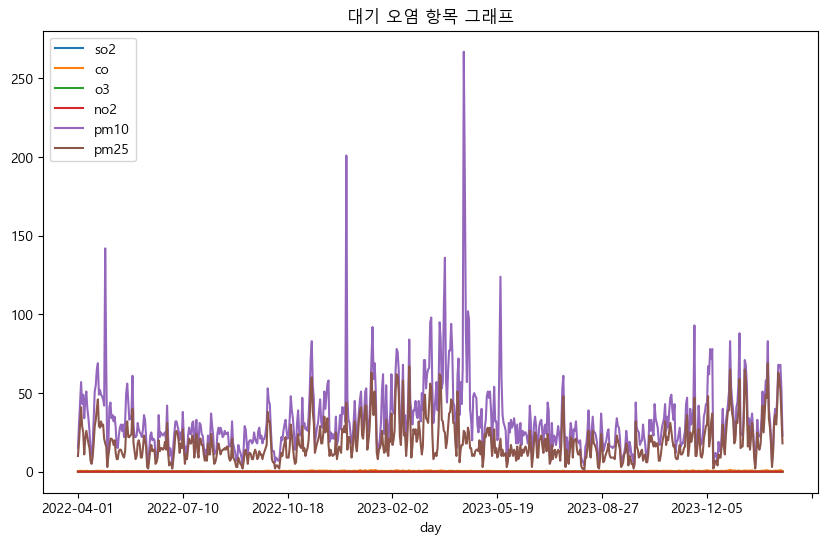

In [7]:
import matplotlib
import matplotlib.pyplot as plt


plt.rc('font', family='Malgun Gothic')

graph_df = data_df.drop(['location'], axis = 1, inplace = False)
graph_df.set_index('day',inplace=True)
#index를 day로 설정하게 되면 따로 컬럼을 지정해주지 않아도 index를 x축으로 설정하고 plot해준다
graph_df.plot(kind='line', figsize=(10, 6))  # kind='line'으로 선형 그래프 지정

plt.title('대기 오염 항목 그래프')  
plt.xlabel('day')  # x 축 레이블 설정
plt.legend(loc='upper left')  # 범례 위치 설정
plt.show()  

#표준화하는 방법 해당 값에 평균 값들을 빼주고 표준편차로 나누어준다 x-mean(x) / 표준편차
#표준화를 하게 되면 0을 중심으로 뭉쳐서 각각의 변수들이 비슷하게 모인다.
#각각의 변수들의 단위를 지운다?

#### - 정규화하여 그래프 그리기 

In [ ]:
from sklearn.preprocessing import StandardScaler
#표준화 해주는 함수이다.

In [9]:
#location과 day는 단위를 살려야하기 때문에 drop으로 제외해준다.
data_df2 = data_df.drop(['location', 'day'], axis = 1, inplace = False)
#fit_transform을 돌리면 해당 값들이 표준화 된다(정규화는 아니고 표준화이다 -> 정규화는 최종데이터 범위가 0~1사이로 나오게 된다.)
data_df2_scaled = StandardScaler().fit_transform(data_df2.values)
data_df2 = pd.DataFrame(data_df2_scaled , index = data_df.index)
data_df2.columns = ['so2','co','o3','no2','pm10','pm25']

In [10]:
#day가 필요하기 때문에 concat으로 그대로 붙여준다.
day_df = data_df[['day']].copy()
graph_df2 = pd.concat([day_df, data_df2], axis=1)

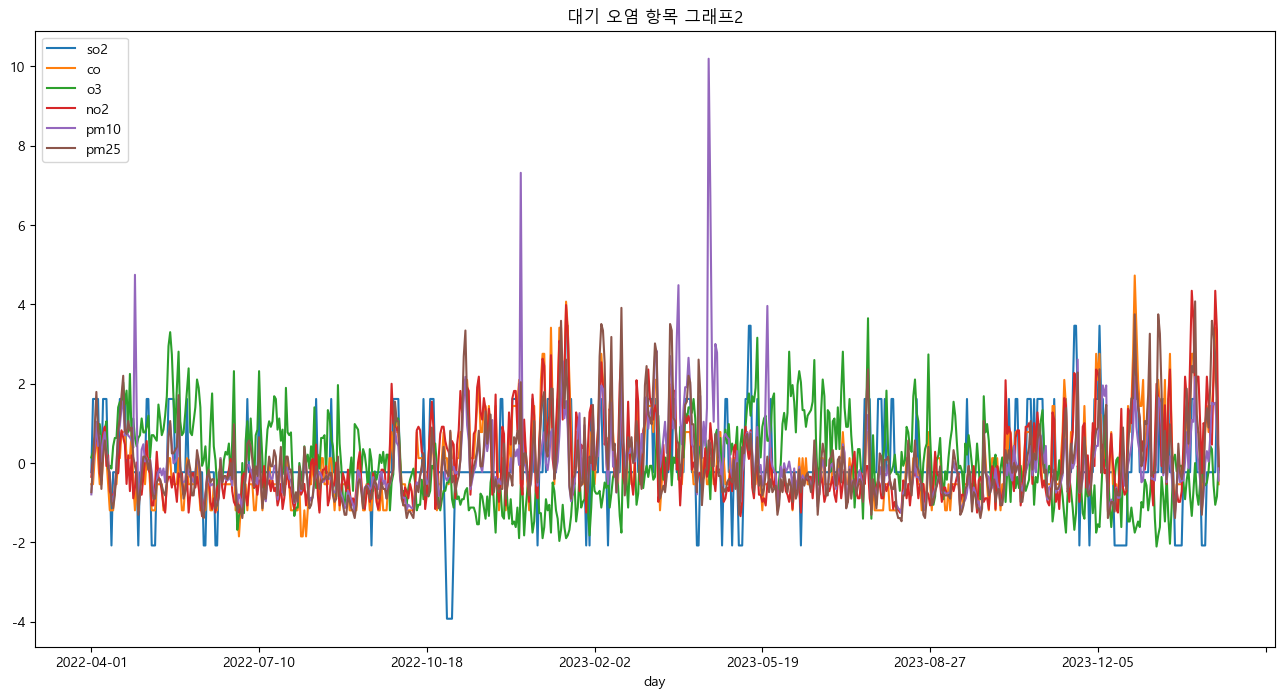

In [11]:
graph_df2.set_index('day',inplace=True)
graph_df2.plot(kind='line', figsize=(16, 8))  
plt.title('대기 오염 항목 그래프2')  
plt.xlabel('day')  
plt.legend(loc='upper left')  
plt.rcParams['axes.unicode_minus'] = False   #음수 부호 깨지지 않게 설정 
plt.show() 

# 5. 분석 모델 구축, 결과 분석 및 시각화

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# X, Y 분할하기
Y_pm10 = data_df['pm10']
Y_pm25 = data_df['pm25']
X = data_df.drop(['location', 'day','pm10', 'pm25'], axis=1, inplace=False)

## (1) 미세먼지 pm10 회귀 분석

### 회귀 분석 모델 구축

In [ ]:
# 훈련용 데이터와 평가용 데이터 분할하기
# pm10이라는 결과에 대한 각각의 가중치들을 보고싶기때문에 y_pm10으로 정답을 지정해준다.
X_train, X_test, Y_pm10_train, Y_pm10_test = train_test_split(X, Y_pm10, test_size=0.3, random_state=156)

In [ ]:
# 선형회귀분석 : 모델 생성
lr_pm10 = LinearRegression()

In [ ]:
# 선형회귀분석 : 모델 훈련
lr_pm10.fit(X_train, Y_pm10_train)

LinearRegression()

In [ ]:
# 선형회귀분석 : 평가 데이터에 대한 예측 수행 -> 예측 결과 Y_predict 구하기
Y_pm10_predict = lr_pm10.predict(X_test)

###  결과 분석 - 모델 평가 

In [ ]:
mse = mean_squared_error(Y_pm10_test, Y_pm10_predict)
rmse = np.sqrt(mse)

print('MSE : {0:.3f}, RMSE : {1:.3f}'.format(mse, rmse))
print('R^2(Variance score) : {0:.3f}'.format(r2_score(Y_pm10_test, Y_pm10_predict)))

MSE : 293.367, RMSE : 17.128
R^2(Variance score) : 0.344


In [ ]:
print('Y_pm10 절편 값: ', lr_pm10.intercept_)
print('회귀 계수 값: ', np.round(lr_pm10.coef_, 1))

Y_pm10 절편 값:  -24.637204220135388
회귀 계수 값:  [2512.8   55.2  444.8  447.3]


In [ ]:
coef = pd.Series(data = np.round(lr_pm10.coef_, 2), index=X.columns)
coef.sort_values(ascending = False)

so2    2512.75
no2     447.27
o3      444.80
co       55.18
dtype: float64

###  회귀 분석 결과를 산점도 + 선형 회귀 그래프로 시각화

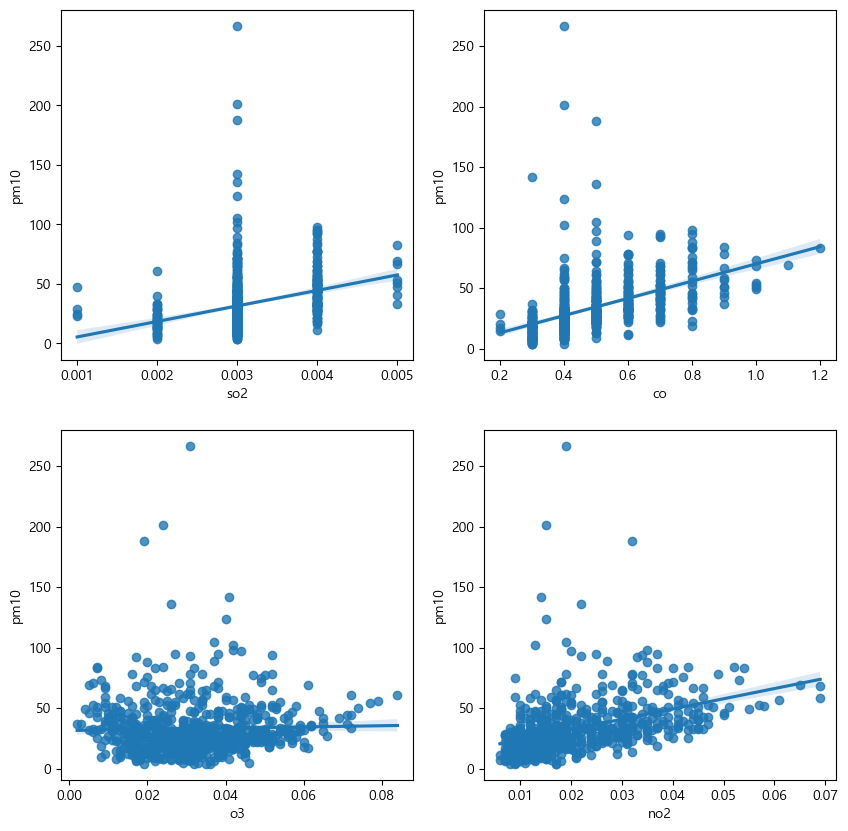

In [ ]:
fig, axs = plt.subplots(figsize=(10, 10), ncols=2, nrows=2)
x_features = ['so2', 'co', 'o3', 'no2']

for i, feature in enumerate(x_features):
      row = int(i/2)
      col = i%2
      sns.regplot(x=feature, y='pm10', data=data_df, ax=axs[row][col])

## (2) 초세먼지 pm25 회귀 분석

### 회귀 분석 모델 구축

In [ ]:
# 훈련용 데이터와 평가용 데이터 분할하기
X_train, X_test, Y_pm25_train, Y_pm25_test = train_test_split(X, Y_pm25, test_size=0.3, random_state=156)

In [ ]:
# 선형회귀분석 : 모델 생성
lr_pm25 = LinearRegression()

In [ ]:
# 선형회귀분석 : 모델 훈련
lr_pm25.fit(X_train, Y_pm25_train)

LinearRegression()

In [ ]:
# 선형회귀분석 : 평가 데이터에 대한 예측 수행 -> 예측 결과 Y_predict 구하기
Y_pm25_predict = lr_pm25.predict(X_test)

###  결과 분석 - 모델 평가 

In [ ]:
mse = mean_squared_error(Y_pm25_test, Y_pm25_predict)
rmse = np.sqrt(mse)

print('MSE : {0:.3f}, RMSE : {1:.3f}'.format(mse, rmse))
print('R^2(Variance score) : {0:.3f}'.format(r2_score(Y_pm25_test, Y_pm25_predict)))

MSE : 51.813, RMSE : 7.198
R^2(Variance score) : 0.661


In [ ]:
print('Y_pm25 절편 값: ', lr_pm25.intercept_)
print('회귀 계수 값: ', np.round(lr_pm25.coef_, 1))

Y_pm25 절편 값:  -22.952459871175417
회귀 계수 값:  [776.   61.5 218.2 136.8]


In [ ]:
coef = pd.Series(data = np.round(lr_pm25.coef_, 2), index=X.columns)
coef.sort_values(ascending = False)

so2    776.01
o3     218.18
no2    136.83
co      61.50
dtype: float64

### - 회귀 분석 결과를 산점도 + 선형 회귀 그래프로 시각화

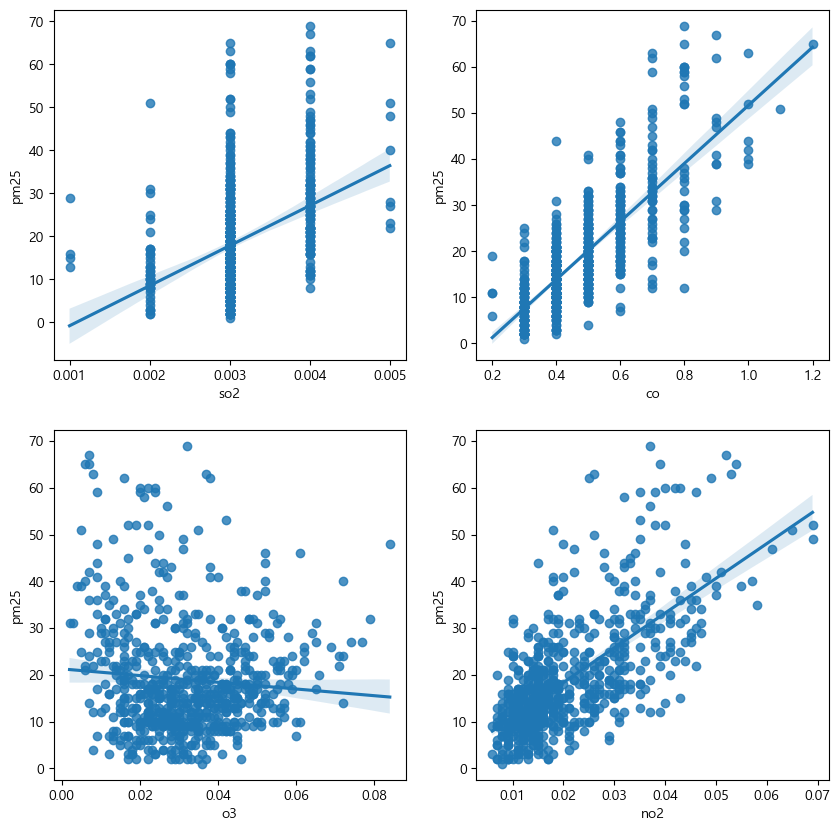

In [ ]:
fig, axs = plt.subplots(figsize=(10, 10), ncols=2, nrows=2)
x_features = ['so2', 'co', 'o3', 'no2']

for i, feature in enumerate(x_features):
      row = int(i/2)
      col = i%2
      sns.regplot(x=feature, y='pm25', data=data_df, ax=axs[row][col])